This notebook runs under semantic conda env on IMac

# Obtaining time varying MPS for CEBRA contrastive learning

Calculating the Spectrograms of all the vocalization library and calculate for each a time varying MPS (FS = 100Hz, MPS window size 100ms).
PCA dimensionality reduction is then apply to all MPSs

In [193]:
# # generalimport pymc
import os
import sys
import glob
import time
import shutil

# External dependencies
import numpy as np
import pandas as pd
import ipympl
# %matplotlib inline
%matplotlib widget
import matplotlib.pyplot as plt
from IPython import display

# sound processing
from soundsig.sound import BioSound, mps, plot_mps, spec_colormap, WavFile

# path to library
path2Library = os.path.expanduser('~/Documents/ZebraFinchVocalizationBank/')


### obtain list of sound wav files

In [22]:
directory = (glob.glob(path2Library + "*Vocalizations"))

# initialize output
filepaths  = []
filenames = []
birdnames = []
calltypes = []
renditions = []
birdage = []


# loop to gather filenames, bird names...
for d in directory :
    filespath_local = (glob.glob(d + "/*.wav"))
    for f in filespath_local :
        filepaths.append(f)
        name = os.path.split(f)[-1]
        filenames.append(name)
        separator_ = name.split('_')
        birdnames.append(separator_[0])
        if 'Adult' in d:
            birdage.append('A')
        else:
            birdage.append('C')
        if len(separator_)==2:
            calltypes.append(separator_[1][7:9])
        elif len(separator_)==3:
            calltypes.append(name[18:20])
        separator2 = name.split('-')
        renditions.append(separator2[-1][0:2])

## Define functions

In [73]:
def cal_spectro_from_sound_wav(n, maxSpectro, minSpectro, normalize = False, PlotFlag=False):
    # this function calculate the spectrogram and save in an h5 file
    # initialize a figure if requested
    if PlotFlag:
        fig, (ax1) = plt.subplots(1,1,figsize=(5,5))
        dh = display.display(fig, display_id=True)
    
    # read wav file
    soundIn = WavFile(file_name = filepaths[n]) 
    size_soundIn = soundIn.data.shape
    if len(size_soundIn)==2:
        if size_soundIn[1]==2:
            soundIn.data = (soundIn.data[:,0] + soundIn.data[:,1])/2
    
    # keep track of annotation features
    duration = len(soundIn.data)/soundIn.sample_rate*1000
    birdname = birdnames[n]
    calltype = calltypes[n].upper()
    rendition = renditions[n]

    # Normalize if wanted
    if normalize :
        maxAmp = np.abs(soundIn.data).max() 
    else :
        maxAmp = 1.0

    # Create BioSound Object and store some values
    myBioSound = BioSound(soundWave=soundIn.data.astype(float)/maxAmp, fs=float(soundIn.sample_rate), emitter = birdname, calltype = calltype)

    # Calculate the spectrogram in dB
    myBioSound.spectroCalc(spec_sample_rate=1000, freq_spacing = 50, min_freq=0, max_freq=10000)

    # get the max and non-Inf min of spectrogram
    soundSpect = np.copy(myBioSound.spectro)
    maxSpectro = np.maximum(soundSpect.max(), maxSpectro)
    minSpectro = np.minimum(soundSpect[np.isfinite(soundSpect)].min(), minSpectro)

    # Plot the spectrogram if requested
    if PlotFlag:
        # load spectrogram
        soundSpect_f = np.copy(myBioSound.fo)
        soundSpect_t = np.copy(myBioSound.to)
        ex = (soundSpect_t[0], soundSpect_t[1] * soundSpect.shape[1]*1000, soundSpect_f.min(), soundSpect_f.max()/1000)
        spec_colormap()   # defined in sound.py
        cmap = plt.get_cmap('SpectroColorMap')
        im1 = ax1.imshow(soundSpect, aspect='auto', origin='lower', cmap=cmap, extent =ex)
        ax1.set_title('Spectrogram voc# ' + str(n) + ' of ' + birdname + ' ' + calltype + ' ' + rendition)
        ax1.set_ylabel('Frequency (kHz)')
        ax1.set_xlabel('Time (ms)')
        plt.tight_layout()
    
    # bundle data
    myBioSound.source_fn = np.string_(filepaths[n])
    myBioSound.emitter = birdname
    myBioSound.type = calltype
    myBioSound.rendition = rendition

    # save the results in a single h5 files
    fname = '%s/%d_%s_%s_%s.h5' % (outpath,n, birdname,calltype,rendition)
    myBioSound.saveh5(fname)
    

    return maxSpectro, minSpectro

In [74]:
def get_tmps_from_sound_wav(n,DBLim = None, FS=100, winMPS=100, normalize = False, PlotFlag=False):
    # this function calculate a time varying mps by sliding a winMPS ms window accross the spectrogram of the input sound with a hop of 1/FS s. The first window starts before the spectrogram and have the first 1/FS s snippet of spectrogram.
    # initialize a figure if requested
    if PlotFlag:
        fig, (ax1, ax2, ax3) = plt.subplots(1,3,figsize=(15,5))
        dh = display.display(fig, display_id=True)
    
    # read wav file
    soundIn = WavFile(file_name = filepaths[n]) 
    size_soundIn = soundIn.data.shape
    if len(size_soundIn)==2:
        if size_soundIn[1]==2:
            soundIn.data = (soundIn.data[:,0] + soundIn.data[:,1])/2
    
    # keep track of annotation features
    birdname = birdnames[n]
    calltype = calltypes[n].upper()
    rendition = renditions[n]

    # Normalize if wanted
    if normalize :
        maxAmp = np.abs(soundIn.data).max() 
    else :
        maxAmp = 1.0

    # Create BioSound Object and store some values
    myBioSound = BioSound(soundWave=soundIn.data.astype(float)/maxAmp, fs=float(soundIn.sample_rate), emitter = birdname, calltype = calltype)

    # Calculate the spectrogram in dB
    myBioSound.spectroCalc(spec_sample_rate=1000, freq_spacing = 50, min_freq=0, max_freq=10000)
    
    # load spectrogram
    soundSpect = np.copy(myBioSound.spectro)
    soundSpect_f = np.copy(myBioSound.fo)
    soundSpect_t = np.copy(myBioSound.to)

    # limit the dynamic range if requested
    if DBLim is not None:
        soundSpect = soundSpect - DBLim
        soundSpect[soundSpect<0] = 0
    else: # make sure that the spectrogram contains no -inf value as we are in dB and when the power is null in the original spectrogram, taking the log (what spectroCalc does) returns -inf
        soundSpect[~np.isfinite(soundSpect)] = soundSpect[np.isfinite(soundSpect)].min()


    # Plot the spectrogram if requested
    if PlotFlag:
        ex = (soundSpect_t[0], soundSpect_t[1] * soundSpect.shape[1]*1000, soundSpect_f.min(), soundSpect_f.max()/1000)
        spec_colormap()   # defined in sound.py
        cmap = plt.get_cmap('SpectroColorMap')
        im1 = ax1.imshow(soundSpect, aspect='auto', origin='lower', cmap=cmap, extent =ex)
        ax1.set_title('Spectrogram voc# ' + str(n) + ' of ' + birdname + ' ' + calltype + ' ' + rendition)
        ax1.set_ylabel('Frequency (kHz)')
        ax1.set_xlabel('Time (ms)')
        plt.tight_layout()
    
        
    #calculate tmps: one MPS every 1/FS seconds on a window of winMPS ms
    tmps = list()
    tmps_t = range(0,int(np.ceil(soundSpect_t[-1]*1000 + winMPS)), int(1/FS*1000)) # identifies the end points of all MPS windows in ms
    dt = np.mean(np.diff(soundSpect_t*1000))
    num_indices_win = int(np.ceil(winMPS/dt)) + 1 # identifies the number of indices in the spectrogram that covers a duration larger or equal to the MPS window size because the sampling frequency of the spectrogram in time is not excatly 1000Hz
    spect_padded = np.pad(soundSpect, ((0,0),(num_indices_win,num_indices_win)), constant_values=soundSpect.min()) # create a zero padded spectrogram in which to iterate
    spect_t_win = np.cumsum(np.ones([num_indices_win,1])*dt)-dt

    for tt_stop in tmps_t[1:]:
        stop_idx_padded = int(np.ceil(tt_stop/dt)+1) + num_indices_win
        start_idx_padded = stop_idx_padded - num_indices_win #find the corresponding start point
        spect_local = spect_padded[:,start_idx_padded:stop_idx_padded]
        if np.ptp(spect_local) == 0:
            tmps.append(None)
            continue     # constant window (digital silence): MPS undefined

        if dt*spect_local.shape[1]<winMPS:
            print('NOTE: Sound duration ' + str(spect_t_win[spect_local.shape[1]-1]) + 's')
        wf, wt, mps_local = mps(spect_local, soundSpect_f,spect_t_win/1000, window=winMPS/1000) # the mps is calulated over a single Gaussian window, and the spectrogram is normalized before taking the FFT by default in mps() flooring all data to spect_local.max()-50

        # stop as soon as the MPS contains NaN or inf
        if not np.all(np.isfinite(mps_local)):
            fig, (ax1, ax2, ax3) = plt.subplots(1,3,figsize=(15,5))
            dh = display.display(fig, display_id=True)
            ex = (soundSpect_t[0], soundSpect_t[1] * soundSpect.shape[1]*1000, soundSpect_f.min(), soundSpect_f.max()/1000)
            spec_colormap()   # defined in sound.py
            cmap = plt.get_cmap('SpectroColorMap')
            im1 = ax1.imshow(soundSpect, aspect='auto', origin='lower', cmap=cmap, extent =ex)
            ax1.set_title('Spectrogram voc# ' + str(n) + ' of ' + birdname + ' ' + calltype + ' ' + rendition)
            ax1.set_ylabel('Frequency (kHz)')
            ax1.set_xlabel('Time (ms)')
            plt.tight_layout()
            plot_spectro_mps(spect_t_win/1000,soundSpect_f,spect_local, wf, wt, mps_local, fig, ax2, ax3, dh)
            raise ValueError(f'Non-finite MPS in {os.path.basename(filepaths[n])}: window ending at {tt_stop} ms '
                             f'(window {len(tmps)} of {len(tmps_t)-1}), '
                             f'NaN: {np.isnan(mps_local).sum()}, inf: {np.isinf(mps_local).sum()}, '
                             f'spect_local shape {spect_local.shape}, min {spect_local.min():.2f}, '
                             f'max {spect_local.max():.2f}, std {spect_local.std():.3g}')
       
        if PlotFlag:
            plot_spectro_mps(spect_t_win/1000,soundSpect_f,spect_local, wf, wt, mps_local, fig, ax2, ax3, dh)

        # remove redundant negative spectral modulations
        mps_local = mps_local[wf>=0 , :]
        wf = wf[wf>=0]
        # flatten the mps
        mps_flat = mps_local.flatten()
        # append the flatten mps to output list
        tmps.append(mps_flat)
    if PlotFlag:
        plt.close() # close the figure at the end or else you end up with an extra plot
    # replace the placeholders of silent windows by NaN rows of the same length as the other MPSs
    n_feat = next(len(m) for m in tmps if m is not None)
    tmps = np.array([np.full(n_feat, np.nan) if m is None else m for m in tmps])


    # bundle data
    myBioSound.tmps = tmps
    myBioSound.tmps_t = tmps_t
    myBioSound.tmps_wf = wf
    myBioSound.tmps_wt = wt
    myBioSound.source_fn = np.string_(filepaths[n])
    myBioSound.emitter = birdname
    myBioSound.type = calltype
    myBioSound.rendition = rendition

    # save the results in a single h5 files
    fname = '%s/%d_%s_%s_%s.h5' % (outpath,n, birdname,calltype,rendition)
    myBioSound.saveh5(fname)

    #return {"tmps": tmps,
    #        "tmps_t": tmps_t,
    #        "tmps_wf": wf,
    #        "tmps_wt": wt,
    #       "h5filepath": fname}

In [170]:
def plot_spectro_mps(to, fo, spectro, wf,wt,mps, vlim, fig, ax1, ax2, dh, MPS_LOG=True, wf_0 = True):
    DBNoise = 60
    # plot the spectrogram
    ex = (to[0], to.max()*1000, fo.min(), fo.max()/1000)
    spec_colormap()   # defined in sound.py
    cmap = plt.get_cmap('SpectroColorMap')
    #im1=ax1.imshow(spectro, aspect='auto', origin='lower', cmap='jet', extent=ex)
    im1=ax1.imshow(spectro, aspect='auto', origin='lower', cmap = cmap, extent=ex)
    #fig.colorbar(im1, ax=ax1,label='dB') 
    ax1.set_title('Spectrogram')
    ax1.set_ylabel('Frequency (kHz)')
    ax1.set_xlabel('Time (ms)')
    plt.tight_layout()

    # plot the MPS
    if not wf_0:
        wf = wf[1:]
        mps = mps[1:,:]
    ex = (wt.min(), wt.max(), wf.min()*1e3, wf.max()*1e3)
    cmap = plt.get_cmap('jet')
    if MPS_LOG:
        logMPS = 10.0*np.log10(mps)
        if not vlim:
            vlim = (logMPS.max()-DBNoise, logMPS.max())
        else:
            vlim = 10.0*np.log10(vlim)
        im2=ax2.imshow(logMPS, interpolation='nearest', aspect='auto', origin='lower', cmap=cmap, extent=ex, vmin = vlim[0], vmax = vlim[1])
        ax2.set_title('Modulation Power Spectrum (dB)')
    else:
    #    if not vlim:
    #        vlim = (mps.max() - 10^DBNoise, mps.max())
        im2=ax2.imshow(mps, interpolation='nearest', aspect='auto', origin='lower', cmap=cmap, extent=ex)
        ax2.set_title('Modulation Power Spectrum (power unit)')

    ax2.set_ylabel('Spectral Frequency (Cycles/KHz)')
    ax2.set_xlabel('Temporal Frequency (Hz)')
    ax2.set_ylim((0,wf.max()*1e3))
   
    plt.tight_layout()

    # update the figure
    dh.update(fig)
    time.sleep(0.1)

In [106]:
def get_tmps_from_spectro_h5(fname, MPSmin, MPSmax,DBLim = None, FS=100, winMPS=100, PlotFlag=True):
    # this function calculate a time varying mps by sliding a winMPS ms window accross the input spectrogram with a hop of 1/FS s. The first window starts before the spectrogram and have the first 1/FS s snippet of spectrogram.
    # initialize a figure if requested
    if PlotFlag:
            fig, (ax1, ax2, ax3) = plt.subplots(1,3,figsize=(15,5))
            dh = display.display(fig, display_id=True)
    
    # retrieve the file number
    n = int(os.path.basename(fname).split('_')[0])

    # read h5 file
    myBioSound = BioSound()
    myBioSound.readh5(fname)

    # load the dB spectrogram
    soundSpect = np.copy(myBioSound.spectro)
    soundSpect_f = np.copy(myBioSound.fo)
    soundSpect_t = np.copy(myBioSound.to)

    # limit the dynamic range if requested
    if DBLim is not None:
        soundSpect = soundSpect - DBLim
        soundSpect[soundSpect<0] = 0
    else: # make sure that the spectrogram contains no -inf value as we are in dB and when the power is null in the original spectrogram, taking the log (what spectroCalc does) returns -inf
        soundSpect[~np.isfinite(soundSpect)] = soundSpect[np.isfinite(soundSpect)].min()

    # Plot the spectrogram if requested
    if PlotFlag:
        ex = (soundSpect_t[0], soundSpect_t[1] * soundSpect.shape[1]*1000, soundSpect_f.min(), soundSpect_f.max()/1000)
        spec_colormap()   # defined in sound.py
        cmap = plt.get_cmap('SpectroColorMap')
        im1 = ax1.imshow(soundSpect, aspect='auto', origin='lower', cmap=cmap, extent =ex)
        ax1.set_title('Spectrogram voc# ' + str(n) + ' of ' + myBioSound.emitter.item().decode() + ' ' + myBioSound.type.item().decode() + ' ' + myBioSound.rendition.item().decode())
        ax1.set_ylabel('Frequency (kHz)')
        ax1.set_xlabel('Time (ms)')
        plt.tight_layout()
        


    # calculate tmps: one MPS every 1/FS seconds on a window of winMPS ms
    tmps = list()
    tmps_t = range(0,int(np.ceil(soundSpect_t[-1]*1000 + winMPS)), int(1/FS*1000)) # identifies the end points of all MPS windows in ms
    dt = np.mean(np.diff(soundSpect_t*1000))
    num_indices_win = int(np.ceil(winMPS/dt)) + 1 # identifies the number of indices in the spectrogram that covers a duration larger or equal to the MPS window size because the sampling frequency of the spectrogram in time is not excatly 1000Hz
    spect_padded = np.pad(soundSpect, ((0,0),(num_indices_win,num_indices_win)), constant_values=soundSpect.min()) # create a zero padded spectrogram in which to iterate
    spect_t_win = np.cumsum(np.ones([num_indices_win,1])*dt)-dt
    
    for tt_stop in tmps_t[1:]:
        stop_idx_padded = int(np.ceil(tt_stop/dt)+1) + num_indices_win
        start_idx_padded = stop_idx_padded - num_indices_win #find the corresponding start point
        spect_local = spect_padded[:,start_idx_padded:stop_idx_padded]
        if np.ptp(spect_local) == 0:
            tmps.append(None)
            continue     # constant window (digital silence): MPS undefined
    
        if dt*spect_local.shape[1]<winMPS:
            print('NOTE: Sound duration ' + str(spect_t_win[spect_local.shape[1]-1]) + 's')
        wf, wt, mps_local = mps(spect_local, soundSpect_f,spect_t_win/1000, window=winMPS/1000, Norm=False) # the mps is calulated over a single Gaussian window, and the spectrogram is NOT normalized before taking the FFT (case by default in mps() flooring all data to spect_local.max()-50)
    
        # stop as soon as the MPS contains NaN or inf
        if not np.all(np.isfinite(mps_local)):
            fig, (ax1, ax2, ax3) = plt.subplots(1,3,figsize=(15,5))
            dh = display.display(fig, display_id=True)
            ex = (soundSpect_t[0], soundSpect_t[1] * soundSpect.shape[1]*1000, soundSpect_f.min(), soundSpect_f.max()/1000)
            spec_colormap()   # defined in sound.py
            cmap = plt.get_cmap('SpectroColorMap')
            im1 = ax1.imshow(soundSpect, aspect='auto', origin='lower', cmap=cmap, extent =ex)
            ax1.set_title('Spectrogram voc# ' + str(n) + ' of ' + myBioSound.emitter.item().decode() + ' ' + myBioSound.type.item().decode() + ' ' + myBioSound.rendition.item().decode())
            ax1.set_ylabel('Frequency (kHz)')
            ax1.set_xlabel('Time (ms)')
            plt.tight_layout()
            plot_spectro_mps(spect_t_win/1000,soundSpect_f,spect_local, wf, wt, mps_local,(), fig, ax2, ax3, dh)
            raise ValueError(f'Non-finite MPS in {os.path.basename(filepaths[n])}: window ending at {tt_stop} ms '
                                f'(window {len(tmps)} of {len(tmps_t)-1}), '
                                f'NaN: {np.isnan(mps_local).sum()}, inf: {np.isinf(mps_local).sum()}, '
                                f'spect_local shape {spect_local.shape}, min {spect_local.min():.2f}, '
                                f'max {spect_local.max():.2f}, std {spect_local.std():.3g}')
           
        if PlotFlag:
            plot_spectro_mps(spect_t_win/1000,soundSpect_f,spect_local, wf, wt, mps_local,(), fig, ax2, ax3, dh)
    
        # remove redundant negative spectral modulations
        mps_local = mps_local[wf>=0 , :]
        wf = wf[wf>=0]
        # flatten the mps
        mps_flat = mps_local.flatten()
        # keep track of max and min values
        MPSmax = np.maximum(MPSmax, mps_flat.max())
        MPSmin = np.minimum(MPSmin, mps_flat.min())
        # append the flatten mps to output list
        tmps.append(mps_flat)
    if PlotFlag:
        plt.close() # close the figure at the end or else you end up with an extra plot
    # replace the placeholders of silent windows by NaN rows of the same length as the other MPSs
    n_feat = next(len(m) for m in tmps if m is not None)
    tmps = np.array([np.full(n_feat, np.nan) if m is None else m for m in tmps])
    
    
    # bundle data
    myBioSound.tmps = tmps
    myBioSound.tmps_t = tmps_t
    myBioSound.tmps_wf = wf
    myBioSound.tmps_wt = wt

    # update the results in a single h5 files
    myBioSound.saveh5(fname)

    return MPSmin, MPSmax
    #return {"tmps": tmps,
    #        "tmps_wf": wf,
    #        "tmps_wt": wt,
    #       "h5filepath": fname}

In [171]:
def check_tmps_from_h5(fname,MPSmin, MPSmax, DBLim = None, MPS_LOG = True, wf_0 = True, winMPS=100):
    # initialize a figure if requested
    fig, (ax1, ax2, ax3) = plt.subplots(1,3,figsize=(15,5))
    dh = display.display(fig, display_id=True)
    # read h5 file
    myBioSound = BioSound()
    myBioSound.readh5(fname)
    # load spectrogram
    soundSpect = np.copy(myBioSound.spectro)
    soundSpect_f = np.copy(myBioSound.fo)
    soundSpect_t = np.copy(myBioSound.to)
    
    # limit the dynamic range of spectrogram if requested
    if DBLim is not None:
        soundSpect = soundSpect - DBLim
        soundSpect[soundSpect<0] = 0
    else: # make sure that the spectrogram contains no -inf value as we are in dB and when the power is null in the original spectrogram, taking the log (what spectroCalc does) returns -inf
        soundSpect[~np.isfinite(soundSpect)] = soundSpect[np.isfinite(soundSpect)].min()

    ex = (soundSpect_t[0], soundSpect_t[1] * soundSpect.shape[1]*1000, soundSpect_f.min(), soundSpect_f.max()/1000)
    spec_colormap()   # defined in sound.py
    cmap = plt.get_cmap('SpectroColorMap')
    im1 = ax1.imshow(soundSpect, aspect='auto', origin='lower', cmap=cmap, extent =ex)
    ax1.set_title('Spectrogram voc# ' + str(n) + ' of ' + myBioSound.emitter.item().decode() + ' ' + myBioSound.type.item().decode() + ' ' + myBioSound.rendition.item().decode())
    ax1.set_ylabel('Frequency (kHz)')
    ax1.set_xlabel('Time (ms)')
    plt.tight_layout()

    
    
    # plot mps every 1/FS seconds on a window of winMPS ms
    dt = np.mean(np.diff(soundSpect_t*1000))
    num_indices_win = int(np.ceil(winMPS/dt)) + 1 # identifies the number of indices in the spectrogram that covers a duration larger or equal to the MPS window size because the sampling frequency of the spectrogram in time is not excatly 1000Hz
    spect_t_win = np.cumsum(np.ones([num_indices_win,1])*dt)-dt
    spect_padded = np.pad(soundSpect, ((0,0),(num_indices_win,num_indices_win))) # create a zero padded spectrogram in which to iterate

    for i,tt_stop in enumerate(myBioSound.tmps_t[1:]):
        stop_idx_padded = int(np.ceil(tt_stop/dt)+1) + num_indices_win
        start_idx_padded = stop_idx_padded - num_indices_win #find the corresponding start point
        spect_local = spect_padded[:,start_idx_padded:stop_idx_padded]
        if dt*spect_local.shape[1]<winMPS:
            print('NOTE: Sound duration ' + str(spect_t_win[spect_local.shape[1]-1]) + 's')
        plot_spectro_mps(spect_t_win/1000,soundSpect_f,spect_local, myBioSound.tmps_wf, myBioSound.tmps_wt, myBioSound.tmps[i].reshape(len(myBioSound.tmps_wf), len(myBioSound.tmps_wt)),(MPSmin,MPSmax), fig, ax2, ax3, dh, MPS_LOG, wf_0)

    plt.close() # close the figure at the end or else you end up with an extra plot

In [222]:
def plot_voc_pca_trajectory(i, pcs=(0, 1, 2), winMPS=100, background=None, n_background=5000, DBNOISE=50):
    # plot the spectrogram, the PC time courses and the trajectory in PCA space of vocalization i
    # i is the position in h5files / tmps_pca_list, pcs are 0-based PC indices (2 or 3 of them)
    # background: optional array of PCA projections (e.g. X_pca) shown as a grey cloud for context
    pcs = list(pcs)
    traj = tmps_pca_list[i][:, pcs]
    with h5py.File(h5files[i], 'r') as f:
        spectro, to, fo, tmps_t = f['spectro'][()], f['to'][()], f['fo'][()], f['tmps_t'][()]
        label = ' '.join(f[k][()].decode() for k in ('emitter', 'type', 'rendition'))
    t_win = tmps_t[1:] - winMPS/2           # center of each MPS window (ms); tmps_t holds the window end points
    valid = np.isfinite(traj).all(axis=1)   # silent windows are NaN rows

    fig = plt.figure(figsize=(14, 6))
    gs = fig.add_gridspec(2, 2)
    ax_s = fig.add_subplot(gs[0, 0])
    ax_t = fig.add_subplot(gs[1, 0], sharex=ax_s)
    ax_p = fig.add_subplot(gs[:, 1], projection='3d' if len(pcs) == 3 else None)

    # spectrogram
    spec = np.where(np.isfinite(spectro), spectro, np.nan)
    vmax = np.nanmax(spec)
    spec_colormap()   # defined in sound.py
    ax_s.imshow(spec, aspect='auto', origin='lower', cmap=plt.get_cmap('SpectroColorMap'), vmin=vmax-DBNOISE, vmax=vmax,
                extent=(to[0]*1000, to[-1]*1000, fo[0]/1000, fo[-1]/1000))
    ax_s.set_ylabel('Frequency (kHz)')
    ax_s.set_title(f'voc {i}: {label}')

    # PC time courses
    for p in pcs:
        ax_t.plot(t_win, tmps_pca_list[i][:, p], '.-', label=f'PC{p+1}')
    ax_t.set_xlim(min(t_win[0], 0), max(t_win[-1], to[-1]*1000))
    ax_t.set_xlabel('Time (ms, center of MPS window)')
    ax_t.set_ylabel('PC score')
    ax_t.legend(fontsize=8)

    # trajectory in PCA space, colored by time
    if background is not None:
        idx = np.random.default_rng(0).choice(len(background), min(n_background, len(background)), replace=False)
        ax_p.scatter(*background[idx][:, pcs].T, s=1, c='lightgray', alpha=0.3)
    ax_p.plot(*traj.T, color='gray', lw=0.8)    # NaN rows leave gaps in the line
    sc = ax_p.scatter(*traj[valid].T, c=t_win[valid], cmap='viridis', s=15)
    first, last = np.where(valid)[0][[0, -1]]
    ax_p.scatter(*traj[first], marker='o', s=80, facecolors='none', edgecolors='g', label='start')
    ax_p.scatter(*traj[last], marker='s', s=80, facecolors='none', edgecolors='r', label='end')
    ax_p.set_xlabel(f'PC{pcs[0]+1}')
    ax_p.set_ylabel(f'PC{pcs[1]+1}')
    if len(pcs) == 3:
        ax_p.set_zlabel(f'PC{pcs[2]+1}')
        # remove the grey panes of the 3D axes, keep thin edges
        for axis in (ax_p.xaxis, ax_p.yaxis, ax_p.zaxis):
            axis.pane.fill = False
            axis.pane.set_edgecolor('lightgray')
    ax_p.legend(fontsize=8)
    fig.colorbar(sc, ax=ax_p, label='Time (ms)', shrink=0.7)

    plt.tight_layout()
    plt.show()


## Calculate all spectrograms

In [58]:
# The directory for storing calculation data
outpath = os.path.expanduser('~/Documents/ZebraFinchVocalizationBank/Spectro_tMPS')
if not os.path.isdir(outpath):
    os.mkdir(outpath)
else:
    shutil.rmtree(outpath) # remove the directory and its content so we can fill in with new data
    os.mkdir(outpath)
    
# --Main--
NVoc = len(filepaths)
spectroMax = -100
spectroMin = 200
for n in range(NVoc):
#for n in {0,1,2} :
    if (n % 100) == 0 :
        print(f"Calculating spectro {n}/{NVoc} sound files")
    spectroMax, spectroMin = cal_spectro_from_sound_wav(n,spectroMax, spectroMin)

print('The max value in dB spectrograms throughout the library is:' + str(spectroMax) + 'dB')
print('The min value in dB spectrograms throughout the library is:' + str(spectroMin) + 'dB')


Calculating spectro 0/3433 sound files
Calculating spectro 100/3433 sound files
Calculating spectro 200/3433 sound files
Calculating spectro 300/3433 sound files
Calculating spectro 400/3433 sound files
Calculating spectro 500/3433 sound files
Calculating spectro 600/3433 sound files
Calculating spectro 700/3433 sound files


/Users/elie/miniconda3/envs/semantic/lib/python3.11/site-packages/soundsig/sound.py:285: RuntimeWarning: divide by zero encountered in log10
  self.spectro = 20*np.log10(np.abs(spec))


Calculating spectro 800/3433 sound files
Calculating spectro 900/3433 sound files
Calculating spectro 1000/3433 sound files
Calculating spectro 1100/3433 sound files
Calculating spectro 1200/3433 sound files
Calculating spectro 1300/3433 sound files
Calculating spectro 1400/3433 sound files
Calculating spectro 1500/3433 sound files
Calculating spectro 1600/3433 sound files
Calculating spectro 1700/3433 sound files
Calculating spectro 1800/3433 sound files
Calculating spectro 1900/3433 sound files
Calculating spectro 2000/3433 sound files
Calculating spectro 2100/3433 sound files
Calculating spectro 2200/3433 sound files
Calculating spectro 2300/3433 sound files
Calculating spectro 2400/3433 sound files
Calculating spectro 2500/3433 sound files
Calculating spectro 2600/3433 sound files
Calculating spectro 2700/3433 sound files
Calculating spectro 2800/3433 sound files
Calculating spectro 2900/3433 sound files


/Users/elie/miniconda3/envs/semantic/lib/python3.11/site-packages/soundsig/sound.py:46: WavFileWarning: Chunk (non-data) not understood, skipping it.
  self.sample_rate, self.data = read_wavfile(file_name)


Calculating spectro 3000/3433 sound files
Calculating spectro 3100/3433 sound files
Calculating spectro 3200/3433 sound files
Calculating spectro 3300/3433 sound files
Calculating spectro 3400/3433 sound files
The max value in dB spectrograms throughout the library is:76.15747492719184dB
The min value in dB spectrograms throughout the library is:-103.10256004233828dB


### Calculate all tmps from spectros

In [107]:
# The directory for storing calculation data
outpath = os.path.expanduser('~/Documents/ZebraFinchVocalizationBank/Spectro_tMPS')

# Fix DBrange
DBRange = 70

MPSmin = 200
MPSmax = -100

# run through every h5 file saved in outpath, sorted by vocalization index n (same order as filepaths)
h5files = sorted(glob.glob(os.path.join(outpath, '*.h5')),
                 key=lambda p: int(os.path.basename(p).split('_')[0]))
for n,fname in enumerate(h5files):
     if (n % 100) == 0 :
          print(f"Calculating tmps {n}/{NVoc} sound files")
     MPSmin, MPSmax = get_tmps_from_spectro_h5(fname, MPSmin, MPSmax, DBLim = spectroMax-DBRange, FS=100, winMPS=100, PlotFlag=False)
print('The max value in power tmps throughout the library is:' + str(MPSmax) + ' or ' + str(10.0*np.log10(MPSmax)) + 'dB')
print('The min value in power tmps throughout the library is:' + str(MPSmin) + ' or ' + str(10.0*np.log10(MPSmin)) + 'dB')

Calculating tmps 0/3433 sound files
Calculating tmps 100/3433 sound files
Calculating tmps 200/3433 sound files
Calculating tmps 300/3433 sound files
Calculating tmps 400/3433 sound files
Calculating tmps 500/3433 sound files
Calculating tmps 600/3433 sound files
Calculating tmps 700/3433 sound files
Calculating tmps 800/3433 sound files
Calculating tmps 900/3433 sound files
Calculating tmps 1000/3433 sound files
Calculating tmps 1100/3433 sound files
Calculating tmps 1200/3433 sound files
Calculating tmps 1300/3433 sound files
Calculating tmps 1400/3433 sound files
Calculating tmps 1500/3433 sound files
Calculating tmps 1600/3433 sound files
Calculating tmps 1700/3433 sound files
Calculating tmps 1800/3433 sound files
Calculating tmps 1900/3433 sound files
Calculating tmps 2000/3433 sound files
Calculating tmps 2100/3433 sound files
Calculating tmps 2200/3433 sound files
Calculating tmps 2300/3433 sound files
Calculating tmps 2400/3433 sound files
Calculating tmps 2500/3433 sound file

## Check a few files

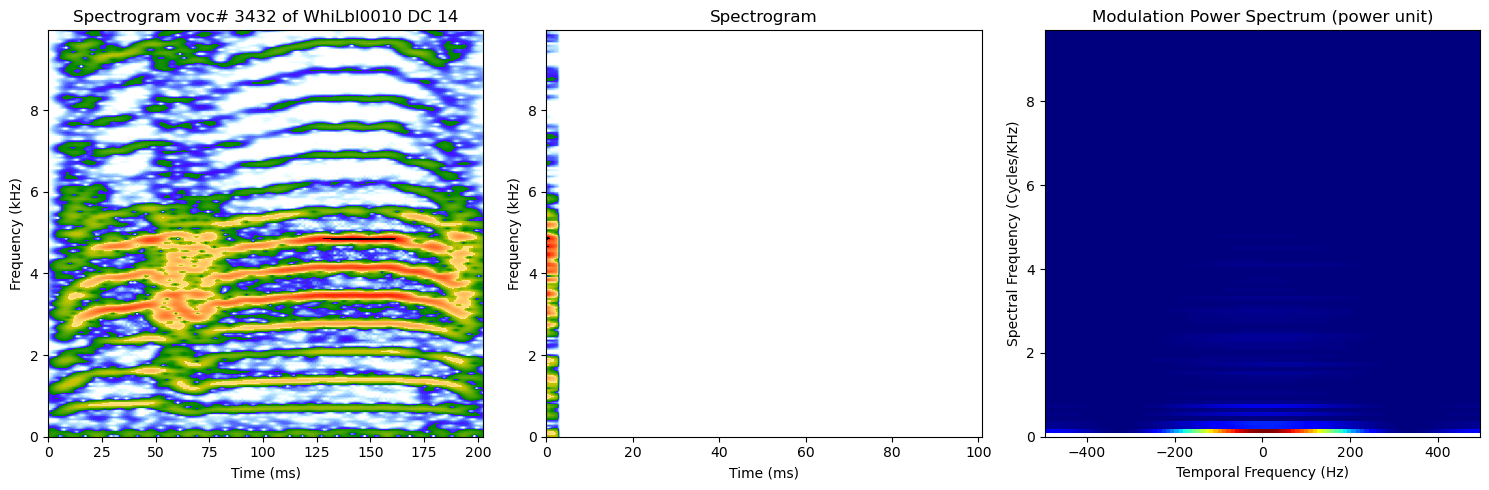

/Users/elie/miniconda3/envs/semantic/lib/python3.11/site-packages/soundsig/sound.py:541: UserWarning: Overwriting the cmap 'SpectroColorMap' that was already in the registry.
  mpl.colormaps.register(cmap=spec_cmap, force=True)


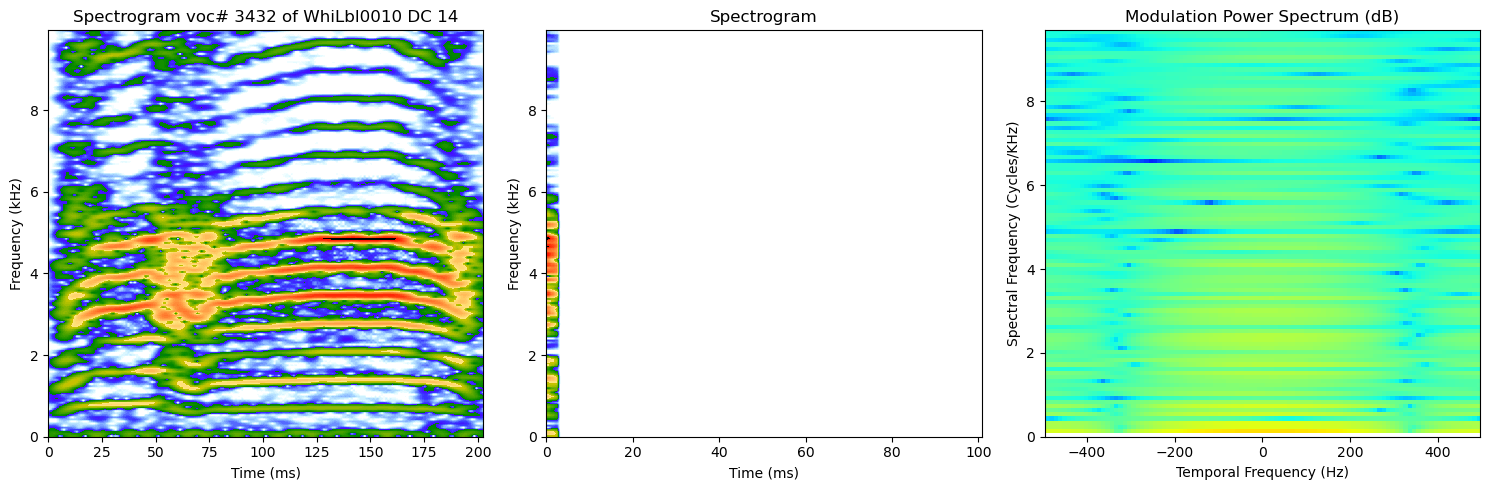

In [214]:
h5files = sorted(glob.glob(os.path.join(outpath, '[0-9]*.h5')),
                 key=lambda p: int(os.path.basename(p).split('_')[0]))

check_tmps_from_h5(h5files[1010],MPSmin, MPSmax, DBLim = spectroMax-DBRange, MPS_LOG = False, wf_0=False, winMPS=100)

check_tmps_from_h5(h5files[1010],MPSmin, MPSmax, DBLim = spectroMax-DBRange, MPS_LOG = True, wf_0 = False, winMPS=100)

In [208]:
i_so = [i for i, p in enumerate(h5files) if os.path.basename(p).split('_')[2] == 'SO']
i_so[0]

24

### PCA on power MPS

gathering data
check tmps size
PCA input: 173798 windows x 9898 features from 3433 vocalizations
Dropping 149 silent windows out of 173798
remove the wf = 0 modulations from the MPSs
Kept 9797 / 9898 features
NaN values: 0, inf values: 0
Windows with non-finite values: 0 / 173649
calculate the log MPSs and fix dynamic range
fit PCA with 500 components
save PCA
80% of variance explained with 4 PCs
90% of variance explained with 7 PCs
95% of variance explained with 13 PCs


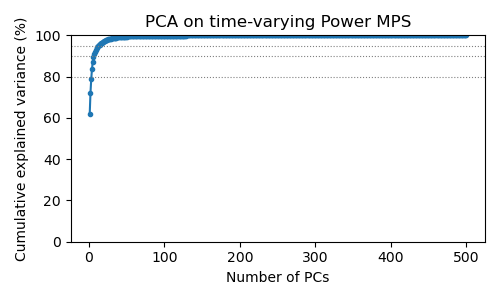

In [233]:
from sklearn.decomposition import PCA
import h5py


N_PCA = 500        # number of PCA dimensions
LOG_MPS = False    # run the PCA on MPS in dB rather than raw power
DB_RANGE = 60      # dynamic range of input MPS (only relevant when LOG_MPS set to true)

# gather tmps from every h5 file saved in outpath, sorted by vocalization index n (same order as filepaths)
print('gathering data')
h5files = sorted(glob.glob(os.path.join(outpath, '[0-9]*.h5')),
                 key=lambda p: int(os.path.basename(p).split('_')[0]))
tmps_list = []
for p in h5files:
    with h5py.File(p, 'r') as f:
        tmps_list.append(np.atleast_2d(f['tmps'][()]))   # read only tmps, not the whole BioSound

# retrieve tmps_wf and tmps_wt to reshape the PCA components
with h5py.File(h5files[0], 'r') as f:
    tmps_wf, tmps_wt = f['tmps_wf'][()], f['tmps_wt'][()]

print('check tmps size')
n_feat = {t.shape[1] for t in tmps_list}
assert len(n_feat) == 1, f'tmps have different numbers of features across vocalizations: {n_feat}'

X = np.concatenate(tmps_list, axis=0)                     # (total number of windows, n MPS features)
voc_lengths = np.array([t.shape[0] for t in tmps_list])   # number of windows per vocalization
print(f'PCA input: {X.shape[0]} windows x {X.shape[1]} features from {len(tmps_list)} vocalizations')

# drop the windows that were marked as silent (NaN rows)
keep = np.isfinite(X).all(axis=1)
print(f'Dropping {(~keep).sum()} silent windows out of {len(keep)}')
X = X[keep]

# zeroes the column that corresponds to the DC offset
#print('remove the DC offset in the MPSs')
#i_wf = np.argmin(np.abs(tmps_wf))     # index of wf = 0
#i_wt = np.argmin(np.abs(tmps_wt))     # index of wt = 0
#col_00 = np.ravel_multi_index((i_wf, i_wt), (len(tmps_wf), len(tmps_wt)))   # = i_wf*len(wt) + i_wt -> 50
#X[:, col_00] = np.ones(X[:, col_00].shape)*X.min()

# remove all features at spectral modulation wf = 0 (this includes the DC offset at wf=0, wt=0)
print('remove the wf = 0 modulations from the MPSs')
WF_grid = np.repeat(tmps_wf, len(tmps_wt))       # wf value of each column of X (same order as flatten())
feat_keep = ~np.isclose(WF_grid, 0)              # True for the columns kept in the PCA
X = X[:, feat_keep]
print(f'Kept {feat_keep.sum()} / {len(feat_keep)} features')

# check for NaN / inf in the matrix of MPS
bad_rows = ~np.isfinite(X).all(axis=1)
print(f'NaN values: {np.isnan(X).sum()}, inf values: {np.isinf(X).sum()}')
print(f'Windows with non-finite values: {bad_rows.sum()} / {X.shape[0]}')

if bad_rows.any():
    voc_index = np.repeat(np.arange(len(tmps_list)), voc_lengths)    # vocalization index for each row of X
    win_index = np.concatenate([np.arange(n) for n in voc_lengths])  # window index within each vocalization
    for i in np.unique(voc_index[bad_rows]):
        wins = win_index[bad_rows & (voc_index == i)]
        h5path = h5files[i]
        with h5py.File(h5path, 'r') as f:
            audiofilepath = f['source_fn'][()].decode()
        print(f'  voc {i} ({os.path.basename(h5path)}): '
              f'{len(wins)}/{voc_lengths[i]} bad windows -> {wins}\n'
              f'      audio file: {audiofilepath}')


# take the log MPS
print('calculate the log MPSs and fix dynamic range')
if LOG_MPS:
    X = 10.0*np.log10(X)
    X = X - (10.0*np.log10(MPSmax)-DB_RANGE) # limit the dynamic range of MPS to DB_RANGE
    X[X<0] = 0


# PCA
print('fit PCA with ' + str(N_PCA) + ' components')
pca = PCA(n_components=N_PCA)
X_pca = pca.fit_transform(X)

# save PCA
print('save PCA')
tag = 'log' if LOG_MPS else 'raw'
pca_fname = os.path.join(outpath, f'pca_tmps_{tag}_{N_PCA}PCs.h5')
if LOG_MPS:
    with h5py.File(pca_fname, 'w') as f:
        f.create_dataset('components', data=pca.components_)            # (N_PCA, n_features)
        f.create_dataset('mean', data=pca.mean_)                         # (n_features,)
        f.create_dataset('explained_variance_ratio', data=pca.explained_variance_ratio_)
        f.create_dataset('log_mps', data=LOG_MPS)             # source data used for this PCA
        f.create_dataset('dynamic_range', data=10.0*np.log10(MPSmax)-DB_RANGE)                    # to apply same pre-processing to future data
        f.create_dataset('feat_keep', data=feat_keep)         # columns of tmps kept (wf = 0 row removed)
        f.create_dataset('tmps_wf', data=tmps_wf)                        # to reshape components into MPSs
        f.create_dataset('tmps_wt', data=tmps_wt)                       # to reshape components into MPSs
else:
    with h5py.File(pca_fname, 'w') as f:
        f.create_dataset('components', data=pca.components_)            # (N_PCA, n_features)
        f.create_dataset('mean', data=pca.mean_)                         # (n_features,)
        f.create_dataset('explained_variance_ratio', data=pca.explained_variance_ratio_)
        f.create_dataset('log_mps', data=LOG_MPS)             # source data used for this PCA
        f.create_dataset('feat_keep', data=feat_keep)         # columns of tmps kept (wf = 0 row removed)
        f.create_dataset('tmps_wf', data=tmps_wf)                        # to reshape components into MPSs
        f.create_dataset('tmps_wt', data=tmps_wt)                       # to reshape components into MPSs

# split the projections back per vocalization, with NaN at the dropped windows so time alignment is kept
X_pca_full = np.full((len(keep), N_PCA), np.nan)
X_pca_full[keep] = X_pca
tmps_pca_list = np.split(X_pca_full, np.cumsum(voc_lengths)[:-1])

# cumulative explained variance
cum_var = np.cumsum(pca.explained_variance_ratio_)*100
plt.figure(figsize=(5, 3))
plt.plot(np.arange(1, N_PCA+1), cum_var, '.-')
for thresh in (80, 90, 95):
    if cum_var[-1] >= thresh:
        n_thresh = np.argmax(cum_var >= thresh) + 1
        plt.axhline(thresh, color='gray', ls=':', lw=0.8)
        print(f'{thresh}% of variance explained with {n_thresh} PCs')
plt.xlabel('Number of PCs')
plt.ylabel('Cumulative explained variance (%)')
plt.title('PCA on time-varying Power MPS')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

80% of variance explained with 4 PCs
90% of variance explained with 7 PCs
95% of variance explained with 13 PCs


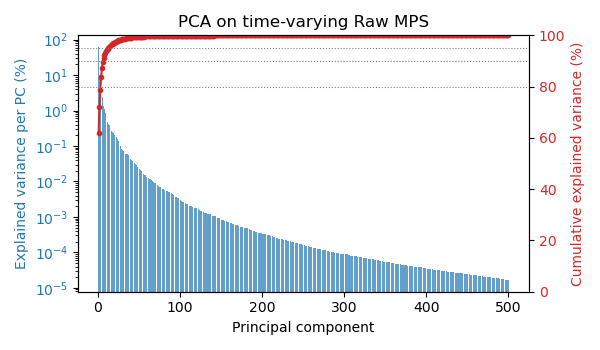

In [234]:
# explained variance: individual components (bars, left axis) and cumulative (line, right axis)
ind_var = pca.explained_variance_ratio_*100
cum_var = np.cumsum(ind_var)
pcs_x = np.arange(1, N_PCA+1)

fig, ax1 = plt.subplots(figsize=(6, 3.5))
ax1.bar(pcs_x, ind_var, color='tab:blue', alpha=0.7)
ax1.set_yscale('log')
ax1.set_xlabel('Principal component')
ax1.set_ylabel('Explained variance per PC (%)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.plot(pcs_x, cum_var, '.-', color='tab:red')
for thresh in (80, 90, 95):
    if cum_var[-1] >= thresh:
        n_thresh = np.argmax(cum_var >= thresh) + 1
        ax2.axhline(thresh, color='gray', ls=':', lw=0.8)
        print(f'{thresh}% of variance explained with {n_thresh} PCs')
ax2.set_ylabel('Cumulative explained variance (%)', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')
ax2.set_ylim(0, 100)

ax1.set_title('PCA on time-varying Raw MPS')
fig.tight_layout()
plt.show()

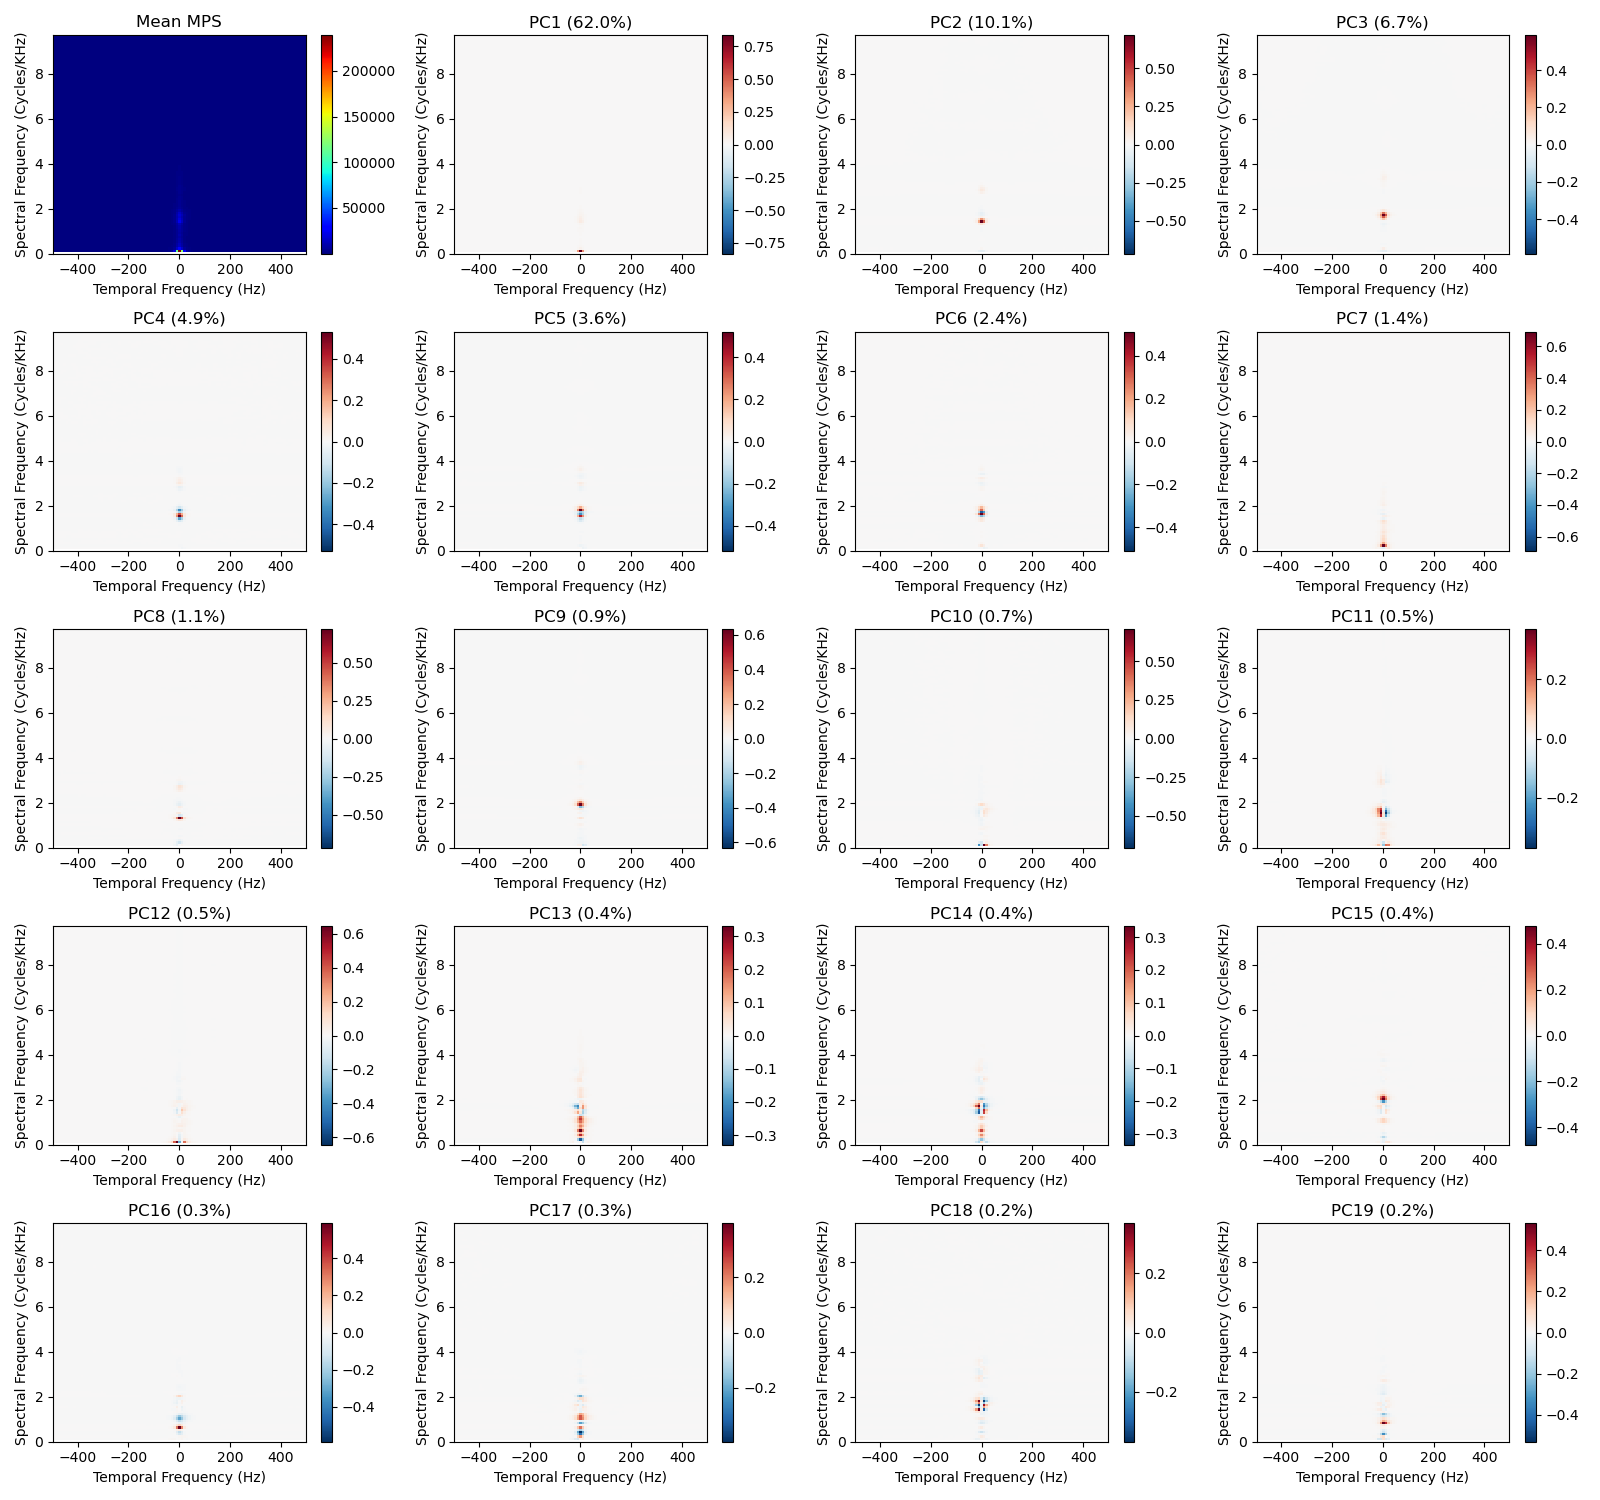

In [235]:
N_SHOW = 19        # number of components to plot
N_COLS = 4

ex = (tmps_wt.min(), tmps_wt.max(), tmps_wf.min()*1e3, tmps_wf.max()*1e3)   # same axes as plot_spectro_mps
n_rows = int(np.ceil((N_SHOW + 1) / N_COLS))
fig, axes = plt.subplots(n_rows, N_COLS, figsize=(4*N_COLS, 3*n_rows), squeeze=False)
axes = axes.flatten()

# Put back the components into a full-size MPS with NaN at the removed row
def to_mps(v):
    full = np.full(len(feat_keep), np.nan)
    full[feat_keep] = v
    return full.reshape(len(tmps_wf), len(tmps_wt))


# mean MPS (what PCA subtracts before projecting)
mean_mps = to_mps(pca.mean_)
im = axes[0].imshow(mean_mps, aspect='auto', origin='lower',
                    cmap='jet', extent=ex, interpolation='nearest')
fig.colorbar(im, ax=axes[0])
axes[0].set_title('Mean MPS' + (' (dB)' if LOG_MPS else ''))

# components: diverging colormap centered on 0 (the sign of each PC is arbitrary)
for k in range(N_SHOW):
    ax = axes[k+1]
    comp = to_mps(pca.components_[k])
    vmax = np.nanmax(np.abs(comp))
    im = ax.imshow(comp, aspect='auto', origin='lower', cmap='RdBu_r', vmin=-vmax, vmax=vmax,
                   extent=ex, interpolation='nearest')
    fig.colorbar(im, ax=ax)
    ax.set_title(f'PC{k+1} ({pca.explained_variance_ratio_[k]*100:.1f}%)')

for ax in axes[N_SHOW+1:]:
    ax.axis('off')
for ax in axes[:N_SHOW+1]:
    ax.set_xlabel('Temporal Frequency (Hz)')
    ax.set_ylabel('Spectral Frequency (Cycles/KHz)')

plt.tight_layout()
plt.show()



/Users/elie/miniconda3/envs/semantic/lib/python3.11/site-packages/soundsig/sound.py:541: UserWarning: Overwriting the cmap 'SpectroColorMap' that was already in the registry.
  mpl.colormaps.register(cmap=spec_cmap, force=True)


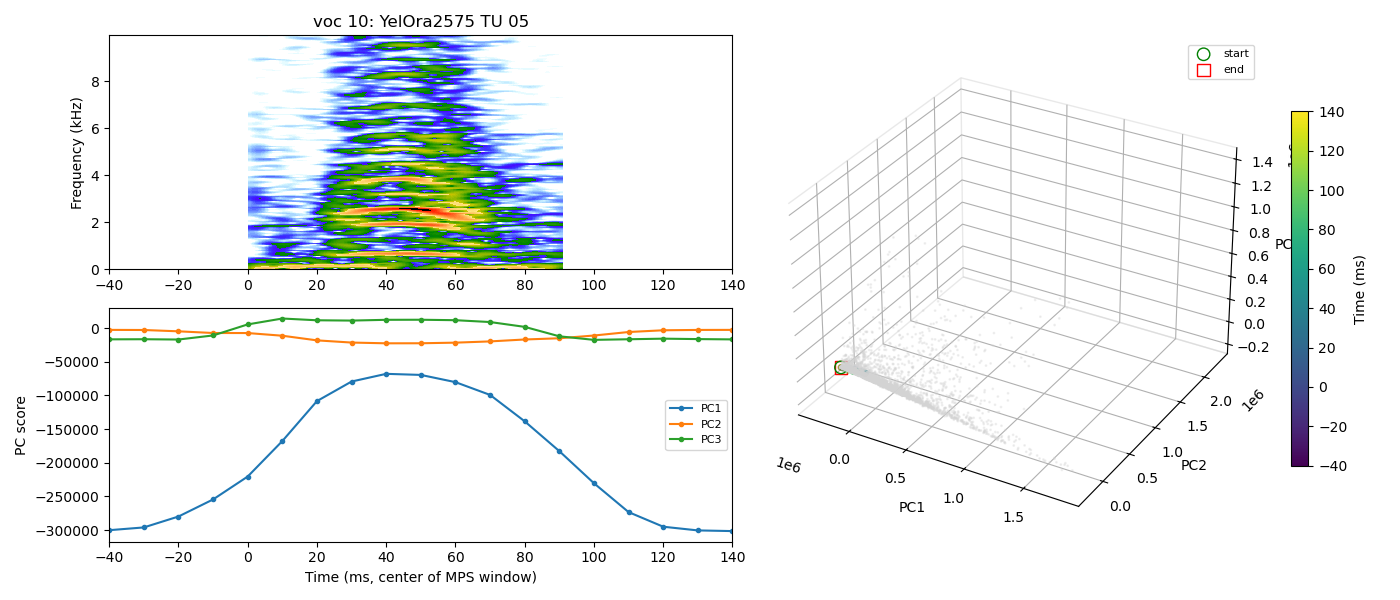

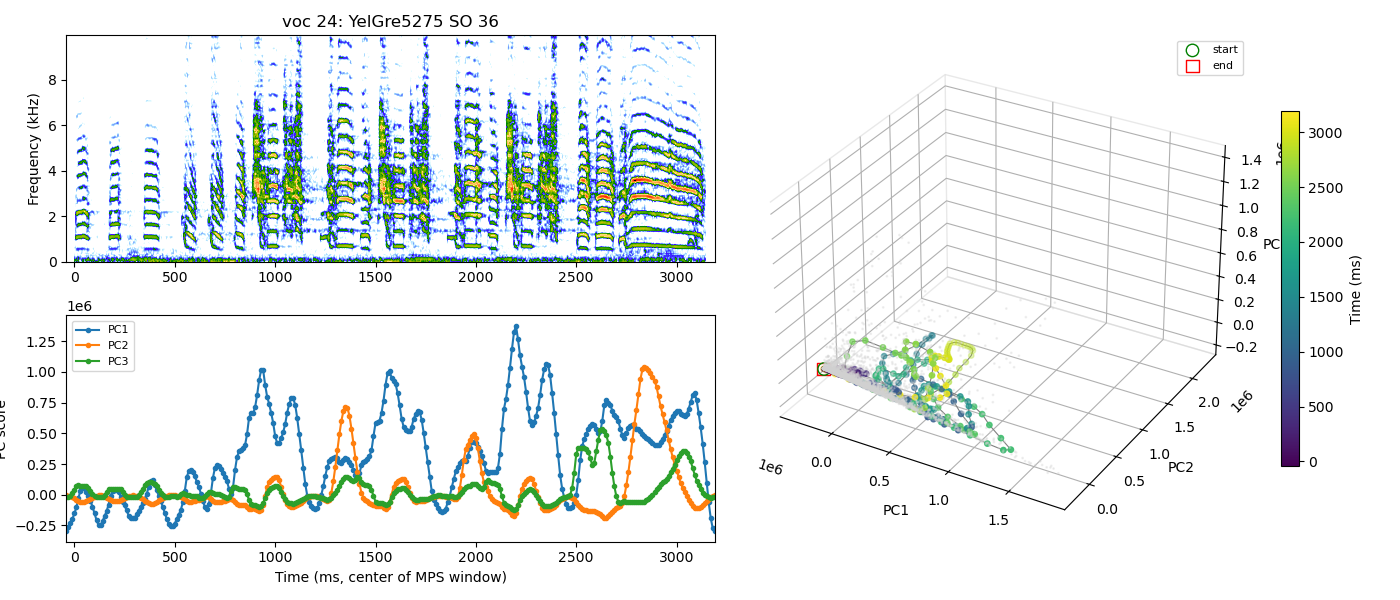

In [236]:
plot_voc_pca_trajectory(10, background=X_pca)
i_so = [i for i, p in enumerate(h5files) if os.path.basename(p).split('_')[2] == 'SO']
plot_voc_pca_trajectory(i_so[0], background=X_pca)

### PCA on Log MPS

In [237]:
from sklearn.decomposition import PCA
import h5py


N_PCA = 500        # number of PCA dimensions
LOG_MPS = True    # run the PCA on MPS in dB rather than raw power
DB_RANGE = 60      # dynamic range of input MPS (only relevant when LOG_MPS set to true)

# gather tmps from every h5 file saved in outpath, sorted by vocalization index n (same order as filepaths)
print('gathering data')
h5files = sorted(glob.glob(os.path.join(outpath, '[0-9]*.h5')),
                 key=lambda p: int(os.path.basename(p).split('_')[0]))
tmps_list = []
for p in h5files:
    with h5py.File(p, 'r') as f:
        tmps_list.append(np.atleast_2d(f['tmps'][()]))   # read only tmps, not the whole BioSound

# retrieve tmps_wf and tmps_wt to reshape the PCA components
with h5py.File(h5files[0], 'r') as f:
    tmps_wf, tmps_wt = f['tmps_wf'][()], f['tmps_wt'][()]

print('check tmps size')
n_feat = {t.shape[1] for t in tmps_list}
assert len(n_feat) == 1, f'tmps have different numbers of features across vocalizations: {n_feat}'

X = np.concatenate(tmps_list, axis=0)                     # (total number of windows, n MPS features)
voc_lengths = np.array([t.shape[0] for t in tmps_list])   # number of windows per vocalization
print(f'PCA input: {X.shape[0]} windows x {X.shape[1]} features from {len(tmps_list)} vocalizations')

# drop the windows that were marked as silent (NaN rows)
keep = np.isfinite(X).all(axis=1)
print(f'Dropping {(~keep).sum()} silent windows out of {len(keep)}')
X = X[keep]

# zeroes the column that corresponds to the DC offset
#print('remove the DC offset in the MPSs')
#i_wf = np.argmin(np.abs(tmps_wf))     # index of wf = 0
#i_wt = np.argmin(np.abs(tmps_wt))     # index of wt = 0
#col_00 = np.ravel_multi_index((i_wf, i_wt), (len(tmps_wf), len(tmps_wt)))   # = i_wf*len(wt) + i_wt -> 50
#X[:, col_00] = np.ones(X[:, col_00].shape)*X.min()

# remove all features at spectral modulation wf = 0 (this includes the DC offset at wf=0, wt=0)
print('remove the wf = 0 modulations from the MPSs')
WF_grid = np.repeat(tmps_wf, len(tmps_wt))       # wf value of each column of X (same order as flatten())
feat_keep = ~np.isclose(WF_grid, 0)              # True for the columns kept in the PCA
X = X[:, feat_keep]
print(f'Kept {feat_keep.sum()} / {len(feat_keep)} features')

# check for NaN / inf in the matrix of MPS
bad_rows = ~np.isfinite(X).all(axis=1)
print(f'NaN values: {np.isnan(X).sum()}, inf values: {np.isinf(X).sum()}')
print(f'Windows with non-finite values: {bad_rows.sum()} / {X.shape[0]}')

if bad_rows.any():
    voc_index = np.repeat(np.arange(len(tmps_list)), voc_lengths)    # vocalization index for each row of X
    win_index = np.concatenate([np.arange(n) for n in voc_lengths])  # window index within each vocalization
    for i in np.unique(voc_index[bad_rows]):
        wins = win_index[bad_rows & (voc_index == i)]
        h5path = h5files[i]
        with h5py.File(h5path, 'r') as f:
            audiofilepath = f['source_fn'][()].decode()
        print(f'  voc {i} ({os.path.basename(h5path)}): '
              f'{len(wins)}/{voc_lengths[i]} bad windows -> {wins}\n'
              f'      audio file: {audiofilepath}')


# take the log MPS
print('calculate the log MPSs and fix dynamic range')
if LOG_MPS:
    X = 10.0*np.log10(X)
    X = X - (10.0*np.log10(MPSmax)-DB_RANGE) # limit the dynamic range of MPS to DB_RANGE
    X[X<0] = 0


# PCA
print('fit PCA with ' + str(N_PCA) + ' components')
pca = PCA(n_components=N_PCA)
X_pca = pca.fit_transform(X)

# save PCA
print('save PCA')
tag = 'log' if LOG_MPS else 'raw'
pca_fname = os.path.join(outpath, f'pca_tmps_{tag}_{N_PCA}PCs.h5')
if LOG_MPS:
    with h5py.File(pca_fname, 'w') as f:
        f.create_dataset('components', data=pca.components_)            # (N_PCA, n_features)
        f.create_dataset('mean', data=pca.mean_)                         # (n_features,)
        f.create_dataset('explained_variance_ratio', data=pca.explained_variance_ratio_)
        f.create_dataset('log_mps', data=LOG_MPS)             # source data used for this PCA
        f.create_dataset('dynamic_range', data=10.0*np.log10(MPSmax)-DB_RANGE)                    # to apply same pre-processing to future spectro data
        f.create_dataset('DBLim_spectro', data = spectroMax-DBRange) # to apply same pre-processing to future sound data.
        f.create_dataset('feat_keep', data=feat_keep)         # columns of tmps kept (wf = 0 row removed)
        f.create_dataset('tmps_wf', data=tmps_wf)                        # to reshape components into MPSs
        f.create_dataset('tmps_wt', data=tmps_wt)                       # to reshape components into MPSs
else:
    with h5py.File(pca_fname, 'w') as f:
        f.create_dataset('components', data=pca.components_)            # (N_PCA, n_features)
        f.create_dataset('mean', data=pca.mean_)                         # (n_features,)
        f.create_dataset('explained_variance_ratio', data=pca.explained_variance_ratio_)
        f.create_dataset('log_mps', data=LOG_MPS)             # source data used for this PCA
        f.create_dataset('feat_keep', data=feat_keep)         # columns of tmps kept (wf = 0 row removed)
        f.create_dataset('tmps_wf', data=tmps_wf)                        # to reshape components into MPSs
        f.create_dataset('tmps_wt', data=tmps_wt)                       # to reshape components into MPSs

# split the projections back per vocalization, with NaN at the dropped windows so time alignment is kept
X_pca_full = np.full((len(keep), N_PCA), np.nan)
X_pca_full[keep] = X_pca
tmps_pca_list = np.split(X_pca_full, np.cumsum(voc_lengths)[:-1])

gathering data
check tmps size
PCA input: 173798 windows x 9898 features from 3433 vocalizations
Dropping 149 silent windows out of 173798
remove the wf = 0 modulations from the MPSs
Kept 9797 / 9898 features
NaN values: 0, inf values: 0
Windows with non-finite values: 0 / 173649
calculate the log MPSs and fix dynamic range
fit PCA with 500 components
save PCA


80% of variance explained with 229 PCs


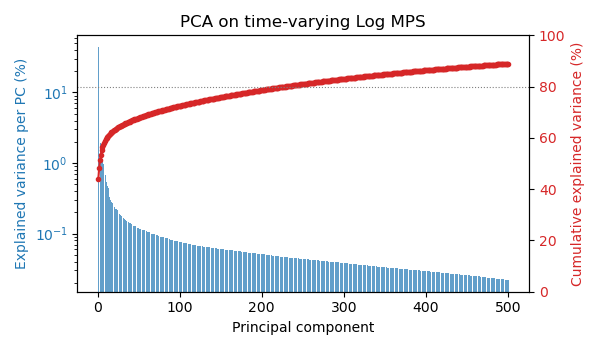

In [238]:
# explained variance: individual components (bars, left axis) and cumulative (line, right axis)
ind_var = pca.explained_variance_ratio_*100
cum_var = np.cumsum(ind_var)
pcs_x = np.arange(1, N_PCA+1)

fig, ax1 = plt.subplots(figsize=(6, 3.5))
ax1.bar(pcs_x, ind_var, color='tab:blue', alpha=0.7)
ax1.set_yscale('log')
ax1.set_xlabel('Principal component')
ax1.set_ylabel('Explained variance per PC (%)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.plot(pcs_x, cum_var, '.-', color='tab:red')
for thresh in (80, 90, 95):
    if cum_var[-1] >= thresh:
        n_thresh = np.argmax(cum_var >= thresh) + 1
        ax2.axhline(thresh, color='gray', ls=':', lw=0.8)
        print(f'{thresh}% of variance explained with {n_thresh} PCs')
ax2.set_ylabel('Cumulative explained variance (%)', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')
ax2.set_ylim(0, 100)

ax1.set_title('PCA on time-varying Log MPS')
fig.tight_layout()
plt.show()

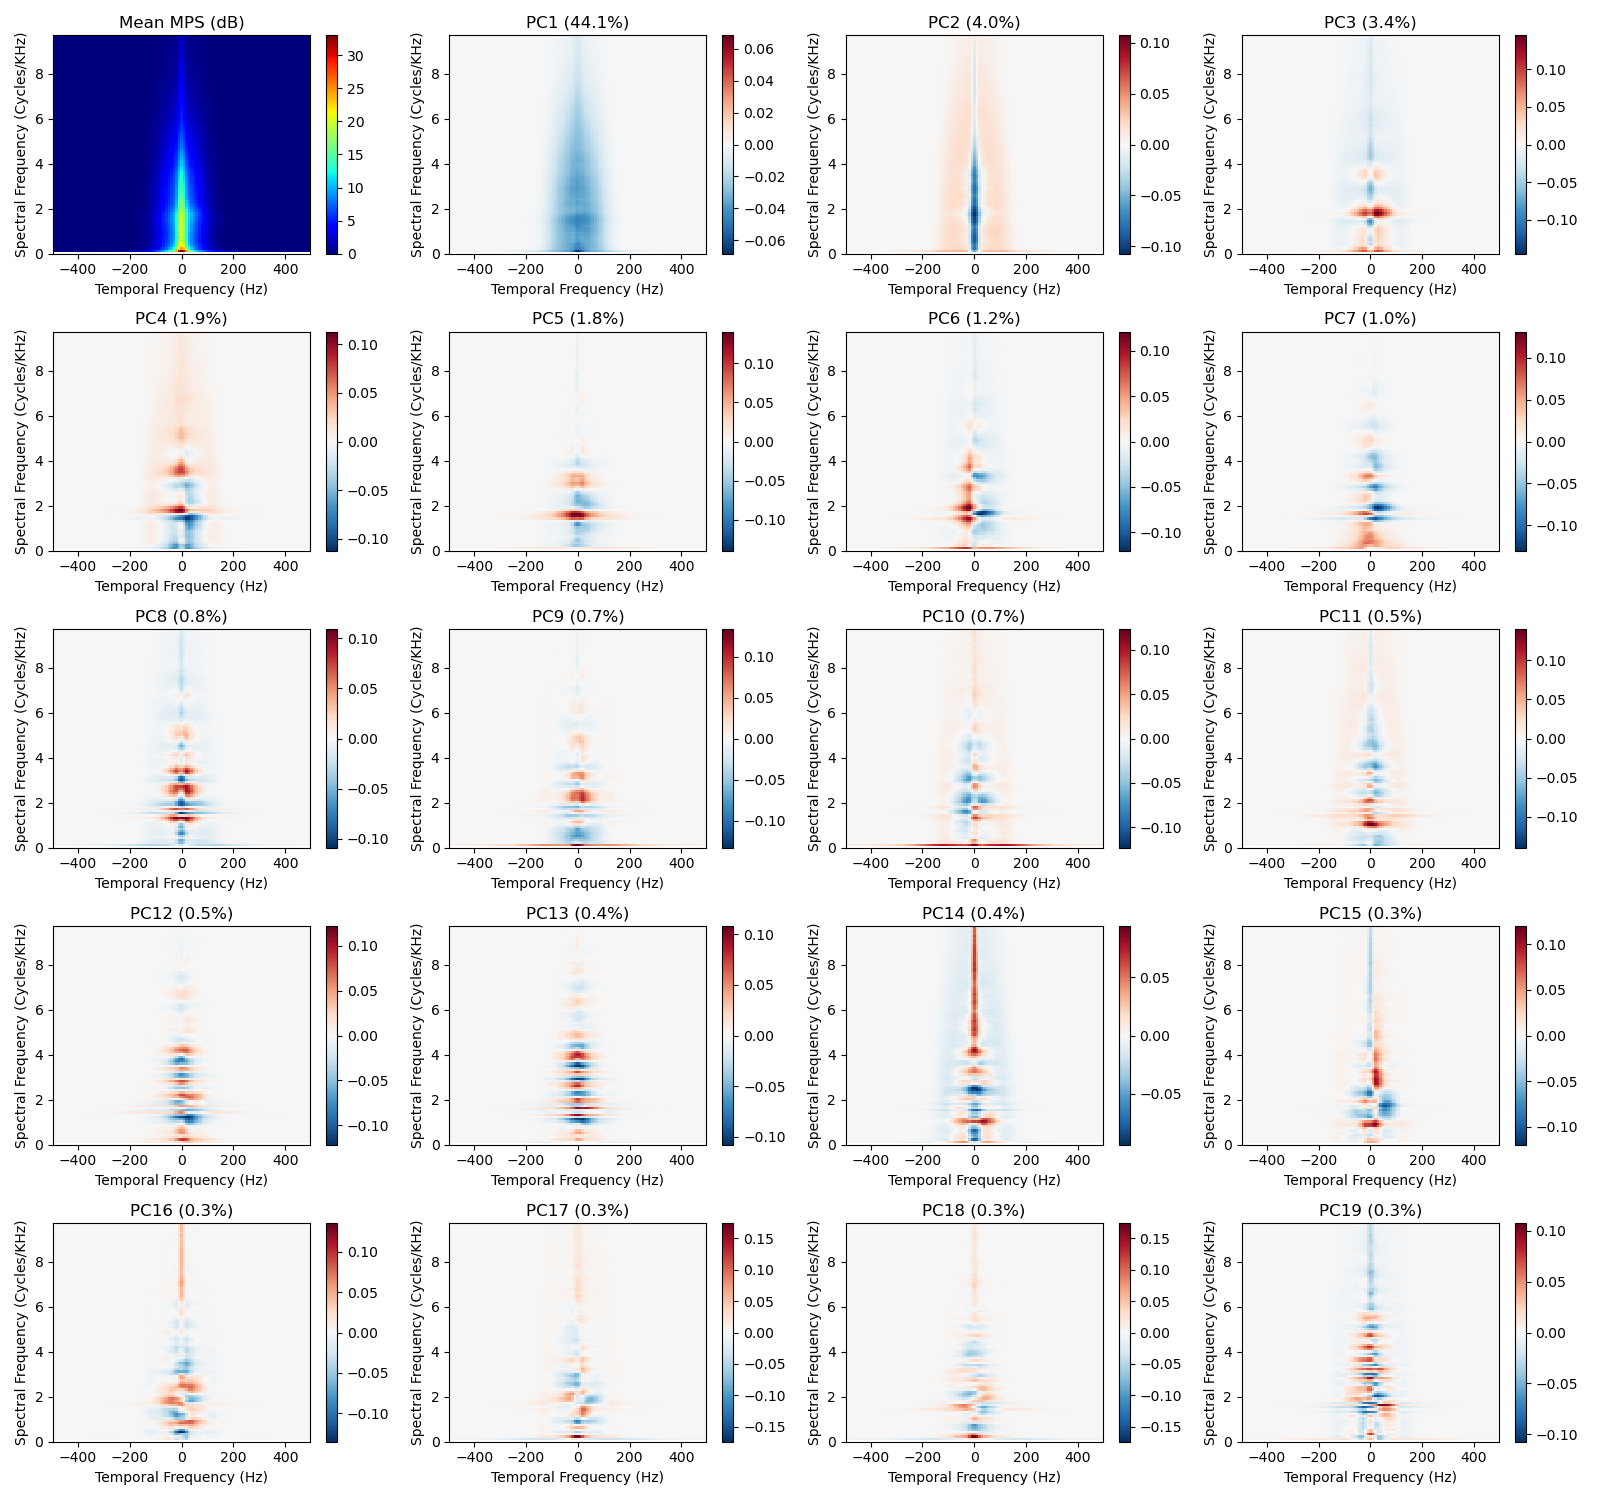

In [239]:
N_SHOW = 19        # number of components to plot
N_COLS = 4
First_PC = 1

ex = (tmps_wt.min(), tmps_wt.max(), tmps_wf.min()*1e3, tmps_wf.max()*1e3)   # same axes as plot_spectro_mps
n_rows = int(np.ceil((N_SHOW + 1) / N_COLS))
fig, axes = plt.subplots(n_rows, N_COLS, figsize=(4*N_COLS, 3*n_rows), squeeze=False)
axes = axes.flatten()

# Put back the components into a full-size MPS with NaN at the removed row
def to_mps(v):
    full = np.full(len(feat_keep), np.nan)
    full[feat_keep] = v
    return full.reshape(len(tmps_wf), len(tmps_wt))


# mean MPS (what PCA subtracts before projecting)
mean_mps = to_mps(pca.mean_)
im = axes[0].imshow(mean_mps, aspect='auto', origin='lower',
                    cmap='jet', extent=ex, interpolation='nearest')
fig.colorbar(im, ax=axes[0])
axes[0].set_title('Mean MPS' + (' (dB)' if LOG_MPS else ''))

# components: diverging colormap centered on 0 (the sign of each PC is arbitrary)
for k in range(N_SHOW):
    ax = axes[k+1]
    comp = to_mps(pca.components_[k + First_PC -1,:])
    vmax = np.nanmax(np.abs(comp))
    im = ax.imshow(comp, aspect='auto', origin='lower', cmap='RdBu_r', vmin=-vmax, vmax=vmax,
                   extent=ex, interpolation='nearest')
    fig.colorbar(im, ax=ax)
    ax.set_title(f'PC{k+First_PC} ({pca.explained_variance_ratio_[k+First_PC-1]*100:.1f}%)')

for ax in axes[N_SHOW+1:]:
    ax.axis('off')
for ax in axes[:N_SHOW+1]:
    ax.set_xlabel('Temporal Frequency (Hz)')
    ax.set_ylabel('Spectral Frequency (Cycles/KHz)')

plt.tight_layout()
plt.show()

In [240]:
pca.components_.shape

(500, 9797)

/Users/elie/miniconda3/envs/semantic/lib/python3.11/site-packages/soundsig/sound.py:541: UserWarning: Overwriting the cmap 'SpectroColorMap' that was already in the registry.
  mpl.colormaps.register(cmap=spec_cmap, force=True)


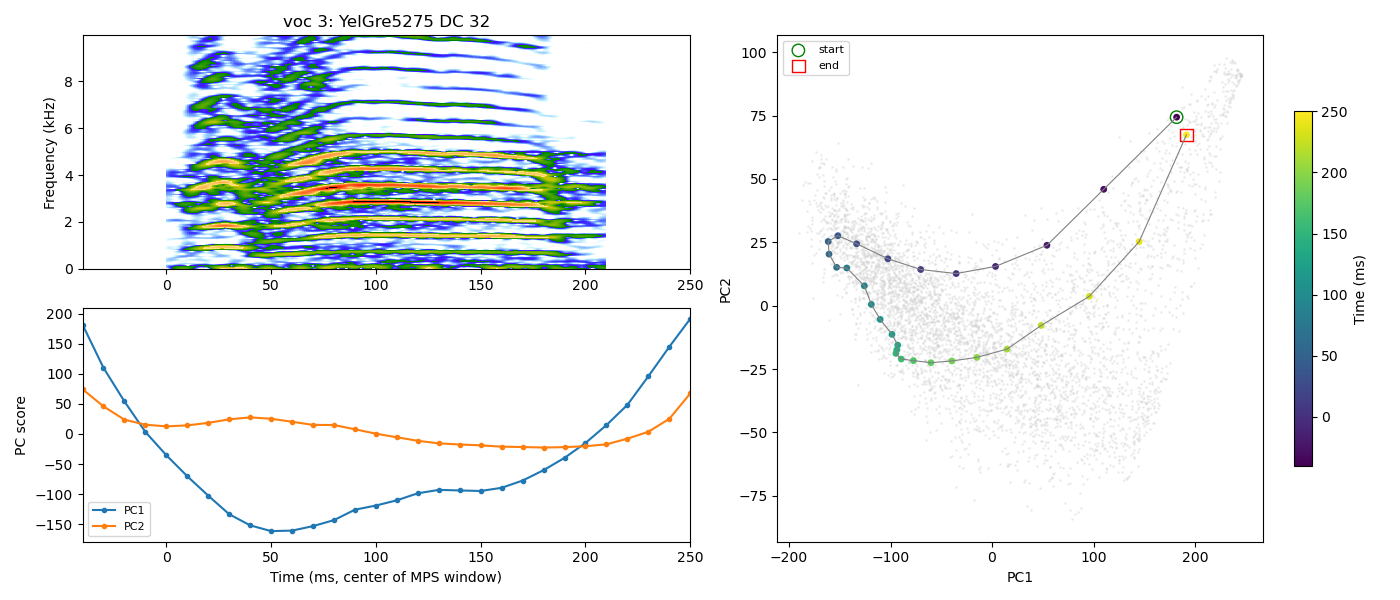

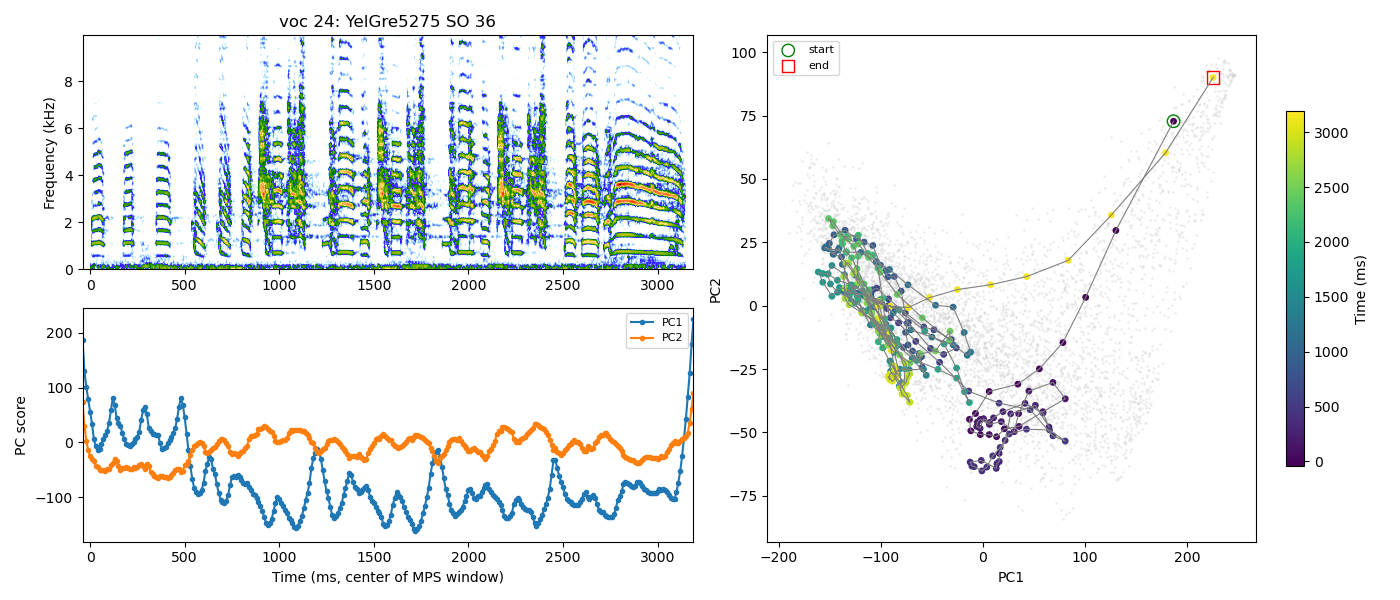

In [241]:
plot_voc_pca_trajectory(3, pcs = (0,1), background=X_pca)
i_so = [i for i, p in enumerate(h5files) if os.path.basename(p).split('_')[2] == 'SO']
plot_voc_pca_trajectory(i_so[0], pcs = (0,1), background=X_pca)

In [242]:
# code to apply to a new dataset of tmps
#N_PCA = 50
#with h5py.File(os.path.join(outpath, f'pca_tmps_{N_PCA}PCs.h5'), 'r') as f:
#    components, mean, log_floor = f['components'][()], f['mean'][()], f['log_floor'][()]
#X_new = 10.0*np.log10(np.maximum(X_new, log_floor))
#X_new_pca = (X_new - mean) @ components.T